# Modeling 1: a physics-based model of post-meal glucose

**Question:** can a small, physically meaningful model predict how each person's glucose responds to a meal, and do its fitted parameters reflect their metabolic health?

**The idea in plain terms.** Think of blood glucose as water in a bathtub:
- a meal is a bucket of water poured in **slowly**, because food has to pass through the gut first;
- the drain is always open (**glucose effectiveness**: the body clears glucose even without extra insulin);
- when the level rises, a second drain opens **a little later and wider** (**insulin action**: insulin is released and takes time to work).

Each person has their own pour speed and drain sizes. We fit those few numbers per person from their meals, then ask whether they predict new meals and whether they line up with HbA1c.

**Plan:**
1. **Baselines** that the model has to beat.
2. **Synthetic test**: can the fitting recover parameters we know?
3. **Fit real people**, test on held-out meals and on held-out people, and compare parameters with HbA1c.

    3b. **Refit on clean meals** (section 6): meals that started from a steady, resting glucose level, because the first fit showed the model can't handle meals that start mid-swing.

Runs on CPU in about 4–5 minutes. Needs numpy, pandas, scipy and matplotlib. Reads the files that `EDA.ipynb` saved in `processed/`.

## 0. Setup

In [3]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.stats import spearmanr

DATA_DIR = Path.cwd()
P = DATA_DIR / "processed"
assert (P / "meal_responses.csv").exists(), "Run EDA.ipynb first: it creates the processed/ folder."

GROUP_ORDER = ["Healthy", "Prediabetes", "T2D"]
GROUP_COLORS = {"Healthy": "#2a78d6", "Prediabetes": "#eb6834", "T2D": "#1baf7a"}
MODEL_COLORS = {"group_mean": "#9aa0a6", "person_mean": "#eda100", "person_per_gram": "#6250d6", "ODE": "#2a78d6"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
RNG = np.random.default_rng(42)

## 1. Build the meal-response dataset

For each isolated meal from the EDA (no other meal within 3 hours), take the Dexcom curve from meal start to 3 hours later on a 5-minute grid. We keep meals with at least 5 g of carbs and at least 80% of the curve observed.

**Split:** within each person, the first 70% of meals (by time) are for fitting and the last 30% for testing. Splitting by time mimics real use: learn from past meals, predict future ones.

In [5]:
GRID = np.arange(0, 181, 5)                       # minutes after meal start

dex = pd.read_csv(P / "dexcom_5min.csv", parse_dates=["timestamp"])
resp = pd.read_csv(P / "meal_responses.csv", parse_dates=["timestamp"])
parts = pd.read_csv(P / "participants.csv")
flags = pd.read_csv(P / "participant_flags.csv")

series = {sid: g.set_index("timestamp")["glucose"] for sid, g in dex.groupby("sid")}

def meal_curve(sid, t0):
    g = series[sid][t0 - pd.Timedelta("20min"): t0 + pd.Timedelta("185min")].dropna()
    rel = (g.index - t0).total_seconds() / 60
    return np.interp(GRID, rel, g.values, left=np.nan, right=np.nan)

meals = resp[resp.carbs >= 5].copy()
meals["obs"] = [meal_curve(r.sid, r.timestamp) for r in meals.itertuples()]
meals = meals[[np.isnan(o).mean() < 0.2 for o in meals.obs]].copy()
meals["Gb"] = meals["baseline"]

# Glucose appearance per gram of carbs depends on body size: alpha = 1000 mg/g * f / (Vg * body weight)
# with f = 0.9 (fraction absorbed) and Vg = 1.88 dL/kg (glucose distribution volume), standard minimal-model values.
bw_kg = parts.set_index("sid")["weight_lb"] * 0.4536
meals["alpha"] = meals.sid.map(1000 * 0.9 / (1.88 * bw_kg))

meals = meals.sort_values(["sid", "timestamp"])
meals["order"] = meals.groupby("sid").cumcount()
meals["n_meals"] = meals.groupby("sid")["sid"].transform("size")
meals["split"] = np.where(meals["order"] < np.ceil(0.7 * meals["n_meals"]), "train", "test")
meals = meals[meals.groupby("sid")["split"].transform(lambda s: (s == "test").sum() >= 1 and (s == "train").sum() >= 4)]

train, test = meals[meals.split == "train"], meals[meals.split == "test"]
print(f"{len(meals)} meals from {meals.sid.nunique()} people | train {len(train)}, test {len(test)}")
meals.groupby("group")["sid"].nunique().reindex(GROUP_ORDER)

831 meals from 36 people | train 597, test 234


group
Healthy        12
Prediabetes    11
T2D            13
Name: sid, dtype: int64

## 2. The physics model

Four quantities change over time after a meal:

| Symbol | Meaning | Units |
|---|---|---|
| Q1, Q2 | carbs in the stomach and in the gut (two steps, so absorption is smooth, not instant) | g |
| G | blood glucose | mg/dL |
| X | insulin action, which builds up when glucose is above baseline | 1/min |

```
dQ1/dt = −ka·Q1                         meal enters the stomach at t = 0 (Q1 = carbs × s)
dQ2/dt =  ka·Q1 − ka·Q2                 then moves through the gut
dG/dt  = −(SG + X)·(G − Gb) + α·ka·Q2   cleared toward baseline Gb; topped up by absorbed carbs
dX/dt  = −p2·X + p2·SI·max(G − Gb, 0)   insulin action follows glucose excess, with a delay
```

**Fitted per person:**
- **ka**: absorption rate (how fast the bucket pours). Peak absorption is about 1/ka minutes after eating.
- **SG**: glucose effectiveness (the always-open drain).
- **SI**: insulin sensitivity (how much the second drain opens per mg/dL of excess glucose).

**Fitted per meal:** **s**, an "effective carbs" factor with a prior centered at 1, which absorbs carb-logging error (EDA section 10.9). At test time we don't know s, so we use s = 1.

**Fixed:** p2 = 0.025/min (how quickly insulin action rises and fades, a typical minimal-model value), and α from body weight.

**Why no insulin data:** CGMacros has no insulin measurements, so insulin action is driven by glucose itself, a simplification of the Bergman minimal model.

In [7]:
P2, T_END = 0.025, 180

def simulate(ka, SG, SI, carbs, Gb, alpha, s=None):
    """Simulate many meals at once (vectorized). Returns glucose at GRID, shape (n_meals, len(GRID))."""
    n = len(carbs)
    s = np.ones(n) if s is None else s
    G, X, Q1, Q2 = Gb.astype(float).copy(), np.zeros(n), carbs * s, np.zeros(n)
    out = np.empty((n, len(GRID))); out[:, 0] = G; k = 1

    def rates(G, X, Q1, Q2):
        excess = G - Gb
        return (-(SG + X) * excess + alpha * ka * Q2,
                -P2 * X + P2 * SI * np.maximum(excess, 0),
                -ka * Q1,
                ka * Q1 - ka * Q2)

    for step in range(1, T_END + 1):                       # Heun (RK2) steps of 1 minute
        a = rates(G, X, Q1, Q2)
        b = rates(G + a[0], X + a[1], Q1 + a[2], Q2 + a[3])
        G, X, Q1, Q2 = (G + (a[0] + b[0]) / 2, X + (a[1] + b[1]) / 2,
                        Q1 + (a[2] + b[2]) / 2, Q2 + (a[3] + b[3]) / 2)
        if step % 5 == 0:
            out[:, k] = G; k += 1
    return out

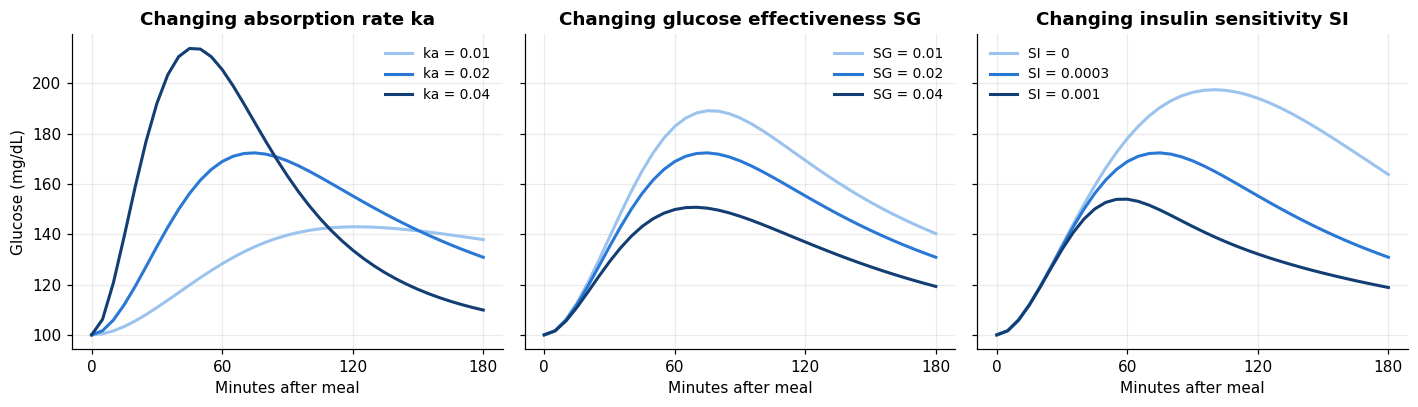

In [8]:
# What each parameter does: vary one at a time around a typical person (60 g carbs, baseline 100)
base = dict(ka=0.02, SG=0.02, SI=3e-4)
variants = {"ka": [0.01, 0.02, 0.04], "SG": [0.01, 0.02, 0.04], "SI": [0, 3e-4, 1e-3]}
labels = {"ka": "absorption rate ka", "SG": "glucose effectiveness SG", "SI": "insulin sensitivity SI"}
shades = ["#9cc3ee", "#2a78d6", "#123e73"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (p, vals) in zip(axes, variants.items()):
    for v, c in zip(vals, shades):
        prm = {**base, p: v}
        ax.plot(GRID, simulate(prm["ka"], prm["SG"], prm["SI"], np.array([60.0]), np.array([100.0]), 6.0)[0],
                color=c, label=f"{p} = {v:g}")
    ax.set(title=f"Changing {labels[p]}", xlabel="Minutes after meal", xticks=range(0, 181, 60))
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Glucose (mg/dL)")
plt.tight_layout(); plt.show()

**Reading the plot:** faster absorption (ka) gives an earlier, taller peak. Bigger drains (SG or SI) give a lower peak and faster return. SG acts from the start, while SI acts later and more strongly when glucose is high. That difference in timing is what lets the fitting tell them apart, *if* the data are clean enough.

### Fitting one person

All of a person's training meals are fitted together, sharing ka, SG and SI, with one s per meal. Parameters are fitted in log space so they stay positive. Two gentle penalties keep the fit sensible:
- each meal's s is pulled toward 1 (carb logs are roughly right on average);
- ka, SG and SI are pulled weakly toward typical values, which matters when a person's data barely inform a parameter.

In [11]:
PRIOR_MU = np.log([0.02, 0.01, 4e-4])     # typical ka, SG, SI
PRIOR_SD, S_SD = 1.0, 0.35                # prior spreads (log scale)
W_PRIOR, W_S = 5.0, 10.0                  # penalty weights, in mg/dL-equivalent units
LB = np.log([0.003, 0.0005, 1e-6]); UB = np.log([0.2, 0.15, 5e-3])

def fit_person(carbs, Gb, obs, alpha, prior_mu=None, prior_sd=None):
    prior_mu = PRIOR_MU if prior_mu is None else prior_mu
    prior_sd = PRIOR_SD if prior_sd is None else prior_sd
    n = len(carbs); seen = ~np.isnan(obs)
    def residuals(x):
        ka, SG, SI = np.exp(x[:3]); s = np.exp(x[3:])
        pred = simulate(ka, SG, SI, carbs, Gb, alpha, s)
        return np.concatenate([(pred - obs)[seen],
                               W_PRIOR * (x[:3] - prior_mu) / prior_sd,
                               W_S * x[3:] / S_SD])
    x0 = np.concatenate([prior_mu, np.zeros(n)])
    lb = np.concatenate([LB, np.full(n, np.log(0.3))]); ub = np.concatenate([UB, np.full(n, np.log(3.0))])
    r = least_squares(residuals, x0, bounds=(lb, ub), x_scale="jac", max_nfev=400)
    return dict(ka=np.exp(r.x[0]), SG=np.exp(r.x[1]), SI=np.exp(r.x[2]), s=np.exp(r.x[3:]), converged=r.success)

## 3. Step 1: baselines to beat

Every model predicts the **rise above baseline** for each test meal (baseline glucose is known when the meal starts).

| Baseline | Prediction for a test meal |
|---|---|
| `group_mean` | average curve of everyone in the same diagnostic group (training meals) |
| `person_mean` | this person's own average curve |
| `person_per_gram` | this person's average curve per gram of carbs × this meal's carbs |

Metrics, per test meal: **RMSE** over the 3-hour curve, **peak error** (height of the highest point) and **time-to-peak error**, all compared with the measured Dexcom curve.

In [13]:
def rise(df):
    return np.vstack([o - b for o, b in zip(df.obs, df.Gb)])

group_curve = {g: np.nanmean(rise(d), 0) for g, d in train.groupby("group")}
person_curve = {sid: np.nanmean(rise(d), 0) for sid, d in train.groupby("sid")}
person_per_gram = {sid: np.nanmean(rise(d) / d.carbs.values[:, None], 0) for sid, d in train.groupby("sid")}

def score(pred_rise, obs_rise):
    m = ~np.isnan(obs_rise); m[0] = False
    return dict(rmse=np.sqrt(np.mean((pred_rise[m] - obs_rise[m]) ** 2)),
                peak_err=abs(np.nanmax(pred_rise) - np.nanmax(obs_rise)),
                tpeak_err=abs(GRID[np.nanargmax(pred_rise)] - GRID[np.nanargmax(obs_rise)]))

rows = []
for r in test.itertuples():
    o = r.obs - r.Gb
    for name, p in {"group_mean": group_curve[r.group], "person_mean": person_curve[r.sid],
                    "person_per_gram": person_per_gram[r.sid] * r.carbs}.items():
        rows.append(dict(sid=r.sid, group=r.group, model=name, **score(p, o)))
baseline_scores = pd.DataFrame(rows)
baseline_scores.groupby("model")[["rmse", "peak_err", "tpeak_err"]].median().round(1)

,rmse,peak_err,tpeak_err
model,,,
group_mean,26.4,22.5,30.0
person_mean,23.9,21.2,20.0
person_per_gram,23.3,20.6,25.0


## 4. Step 2: can the fitting recover known parameters?

Before trusting fitted parameters on real people, test the fitting on **fake people whose parameters we chose**. Each fake person gets 14 meals with carbs drawn from the real data, a random baseline, 5 mg/dL of measurement noise and ±25% carb-logging error that the fitter isn't told about. If the fitter can't recover parameters here, it never will on real data.

Fitted 25 synthetic people in 48 s


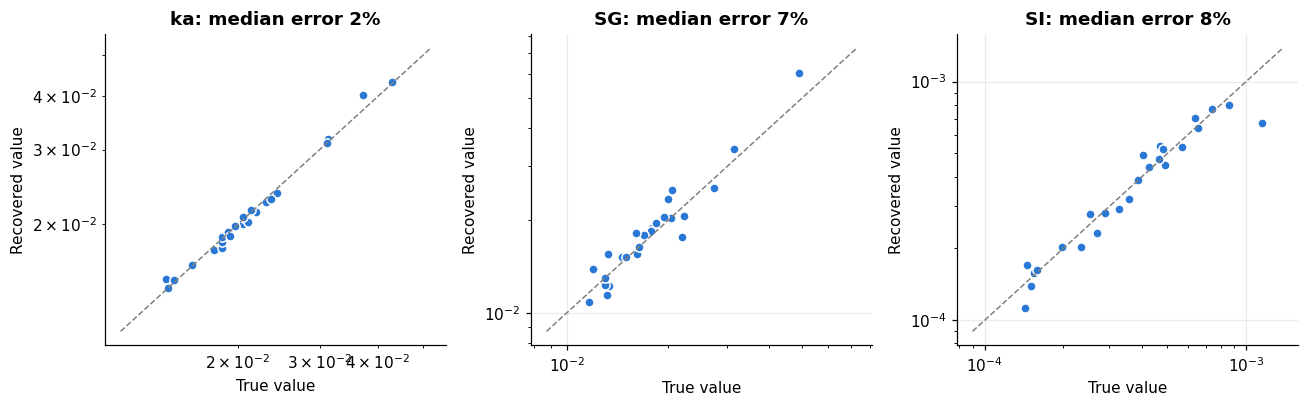

Correlation between recovered SG and SI (should be near 0): 0.2


In [15]:
carb_pool = meals.carbs.values
true_p, est_p = [], []
t0 = time.time()
for i in range(25):
    ka, SG, SI = np.exp(RNG.normal(np.log([0.02, 0.02, 3e-4]), [0.3, 0.4, 0.6]))
    n = 14
    c = RNG.choice(carb_pool, n); Gb = RNG.uniform(90, 130, n); alpha = 6.0
    s_true = np.exp(RNG.normal(0, 0.25, n))                                  # hidden carb-logging error
    obs = simulate(ka, SG, SI, c, Gb, alpha, s_true) + RNG.normal(0, 5, (n, len(GRID)))
    f = fit_person(c, Gb, obs, alpha)
    true_p.append([ka, SG, SI]); est_p.append([f["ka"], f["SG"], f["SI"]])
true_p, est_p = np.array(true_p), np.array(est_p)
print(f"Fitted 25 synthetic people in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for j, (ax, name) in enumerate(zip(axes, ["ka", "SG", "SI"])):
    ax.loglog(true_p[:, j], est_p[:, j], "o", color="#2a78d6", mec="white")
    lim = [min(true_p[:, j].min(), est_p[:, j].min()) * 0.8, max(true_p[:, j].max(), est_p[:, j].max()) * 1.2]
    ax.plot(lim, lim, "--", color="gray", lw=1)
    err = np.median(np.abs(est_p[:, j] / true_p[:, j] - 1)) * 100
    ax.set(title=f"{name}: median error {err:.0f}%", xlabel="True value", ylabel="Recovered value")
plt.tight_layout(); plt.show()
print("Correlation between recovered SG and SI (should be near 0):",
      round(np.corrcoef(np.log(est_p[:, 1]), np.log(est_p[:, 2]))[0, 1], 2))

**Reading this:** points on the dashed line mean perfect recovery. All three parameters land close to it and the SG–SI correlation is near zero, the model is **identifiable**: with clean enough data, it can separate absorption, baseline clearance and insulin action.

## 5. Step 3: fit real people

Two passes:
1. Fit everyone with the generic prior.
2. Recenter the prior on the **population median** of pass 1 and refit with a tighter prior. People with weak data are then pulled toward what's typical instead of drifting to extreme values. (empirical Bayes, or "borrowing strength.")

In [18]:
def fit_everyone(df, prior_mu=None, prior_sd=None):
    out = {}
    for sid, g in df.groupby("sid"):
        out[sid] = fit_person(g.carbs.values, g.Gb.values, np.vstack(g.obs.values), g.alpha.iloc[0], prior_mu, prior_sd)
    return out

t0 = time.time()
fits_pass1 = fit_everyone(train)
pop_mu = np.log(pd.DataFrame({s: [f["ka"], f["SG"], f["SI"]] for s, f in fits_pass1.items()}).T).median().values
fits = fit_everyone(train, prior_mu=pop_mu, prior_sd=0.5)
print(f"Fitted {len(fits)} people twice in {time.time() - t0:.0f} s")
print("Population medians: ka = %.4f /min, SG = %.4f /min, SI = %.2e" % tuple(np.exp(pop_mu)))

params = pd.DataFrame({s: {k: f[k] for k in ["ka", "SG", "SI", "converged"]} for s, f in fits.items()}).T
params[["ka", "SG", "SI"]] = params[["ka", "SG", "SI"]].astype(float)
params = params.join(flags.set_index("sid")[["group", "A1c", "groups_agree", "cycle_status"]])
params["absorption_peak_min"] = 1 / params["ka"]
print("All fits converged:", bool(params.converged.all()))
params.groupby("group")[["ka", "absorption_peak_min", "SG", "SI"]].median().reindex(GROUP_ORDER)

Fitted 36 people twice in 294 s
Population medians: ka = 0.0190 /min, SG = 0.0455 /min, SI = 6.57e-06
All fits converged: True


,ka,absorption_peak_min,SG,SI
group,,,,
Healthy,0.019331,51.730967,0.115308,0.000006
Prediabetes,0.018967,52.723757,0.039944,0.000004
T2D,0.018490,54.083928,0.040003,0.000002


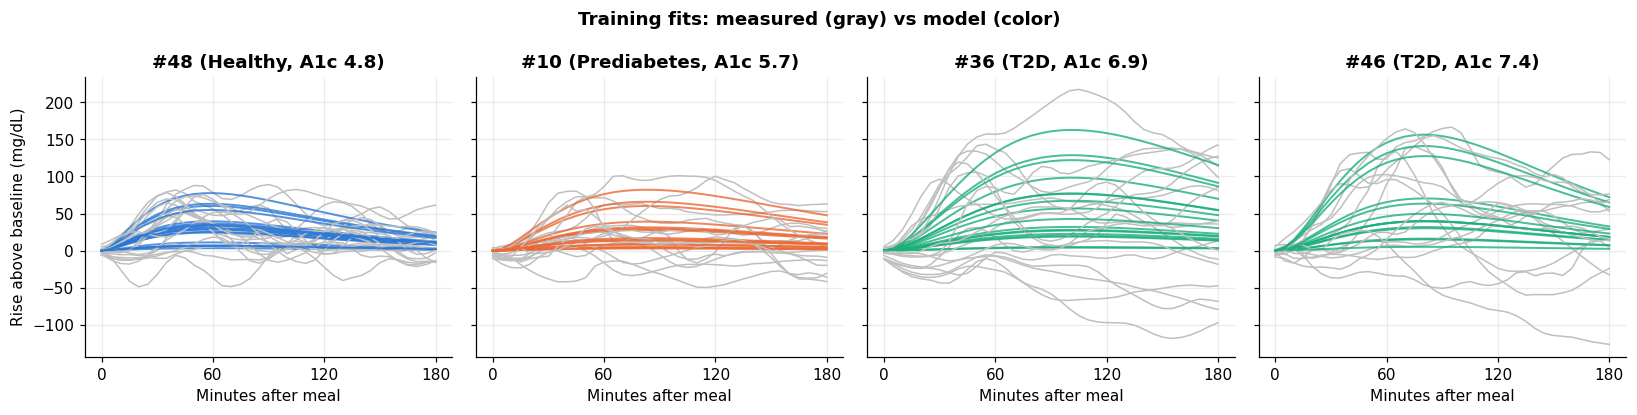

In [19]:
# How well does the model fit the meals it was trained on? Four example people across groups.
examples = (params.reset_index().rename(columns={"index": "sid"})
            .sort_values("A1c").iloc[[2, 14, 26, -3]]["sid"].tolist())
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, sid in zip(axes, examples):
    g = train[train.sid == sid]; f = fits[sid]
    pred = simulate(f["ka"], f["SG"], f["SI"], g.carbs.values, g.Gb.values, g.alpha.iloc[0], f["s"])
    for o, p, b in zip(g.obs, pred, g.Gb):
        ax.plot(GRID, o - b, color="0.75", lw=1)
        ax.plot(GRID, p - b, color=GROUP_COLORS[params.loc[sid, "group"]], lw=1.3, alpha=0.8)
    ax.set(title=f"#{sid} ({params.loc[sid, 'group']}, A1c {params.loc[sid, 'A1c']})",
           xlabel="Minutes after meal", xticks=range(0, 181, 60))
axes[0].set_ylabel("Rise above baseline (mg/dL)")
fig.suptitle("Training fits: measured (gray) vs model (color)", fontweight="bold")
plt.tight_layout(); plt.show()

## 6. Step 3b: refit on clean meals

### Why this step

The training-fit plot above shows a problem: many measured curves (gray) fall **well below** the pre-meal level, sometimes by 50–120 mg/dL, while the model (color) never can. In the model, carbs only push glucose up and clearance only pulls it back **to the starting value**, so it can't produce a curve that ends lower than it began.

Checking the data showed why. For many meals, the pre-meal reading wasn't the person's resting level: glucose was still coming down from something earlier (an unlogged snack, a previous meal, a late log). It's like measuring a ball's height mid-bounce and assuming that height is the floor. Meals where glucose was already moving before eating dip far more often, and the problem is worst in T2D.

So before fixing the model itself, we refit it using only **clean meals**: meals that started from a calm, resting glucose level, which is the situation the equations describe.

### The rule: decide using only what was known *before* the meal

A meal is **clean** if, at the moment of eating:
1. **Glucose was steady:** it changed by no more than 15 mg/dL over the previous hour, and
2. **Glucose wasn't elevated:** it was no more than 30 mg/dL above the person's **resting level** (their median overnight glucose, 02:00–05:00, using only nights from their training period).

We deliberately **don't** use anything that happens after the meal, such as whether the curve dipped. At prediction time you can't know that in advance, so filtering on it would make results look better than they really are. Dip rates are shown below only as evidence that the rule works.

In [21]:
def glucose_near(sid, t, window="10min"):
    g = series[sid][t - pd.Timedelta(window): t + pd.Timedelta(window)].dropna()
    return g.mean() if len(g) else np.nan

# 1. How much glucose changed in the hour before eating
meals["pre_change_60"] = meals["Gb"] - [glucose_near(r.sid, r.timestamp - pd.Timedelta("60min")) for r in meals.itertuples()]

# 2. Resting level: median overnight glucose, using only nights before the person's first test meal
first_test = test.groupby("sid")["timestamp"].min()
def resting_level(sid):
    g = series[sid]
    g = g[(g.index < first_test[sid]) & (g.index.hour >= 2) & (g.index.hour < 5)]
    return g.median()
meals["resting"] = meals["sid"].map({sid: resting_level(sid) for sid in meals.sid.unique()})
meals["above_resting"] = meals["Gb"] - meals["resting"]

STEADY_MG_DL, ELEVATED_MG_DL = 15, 30
meals["clean"] = (meals["pre_change_60"].abs() <= STEADY_MG_DL) & (meals["above_resting"] <= ELEVATED_MG_DL)

# Evidence only (NOT used for selection): did the curve dip more than 30 mg/dL below its starting value?
meals["dipped"] = [np.nanmin(o - b) < -30 for o, b in zip(meals.obs, meals.Gb)]

print(f"Clean meals: {meals.clean.sum()} of {len(meals)} ({meals.clean.mean():.0%})")
summary = meals.groupby("group").agg(meals=("clean", "size"), clean_share=("clean", "mean"))
summary["dip_rate_clean"] = meals[meals.clean].groupby("group")["dipped"].mean()
summary["dip_rate_not_clean"] = meals[~meals.clean].groupby("group")["dipped"].mean()
pct = ["clean_share", "dip_rate_clean", "dip_rate_not_clean"]
summary[pct] = (summary[pct] * 100).round(0)
summary.reindex(GROUP_ORDER).rename(columns={c: c + " (%)" for c in pct})

Clean meals: 580 of 831 (70%)


,meals,clean_share (%),dip_rate_clean (%),dip_rate_not_clean (%)
group,,,,
Healthy,261,77.0,5.0,30.0
Prediabetes,271,74.0,12.0,27.0
T2D,299,60.0,18.0,36.0


In [22]:
# Which part of the rule matters? Dip rate by what glucose was doing in the hour before the meal
trend = pd.cut(meals["pre_change_60"], [-np.inf, -STEADY_MG_DL, STEADY_MG_DL, np.inf],
               labels=["falling before meal", "steady", "rising before meal"])
by_trend = meals.groupby(trend, observed=True).agg(meals=("dipped", "size"), dip_rate=("dipped", "mean"),
                                                    median_start_glucose=("Gb", "median"))
by_trend["dip_rate"] = (by_trend["dip_rate"] * 100).round(0)
by_trend.rename(columns={"dip_rate": "dip_rate (%)"}).round(0)

,meals,dip_rate (%),median_start_glucose
pre_change_60,,,
falling before meal,185,28.0,123.0
steady,591,13.0,116.0
rising before meal,52,37.0,146.0


**Reading this:** meals that start while glucose is rising or falling dip far more often than meals that start steady. In the build run, 13% of steady meals dipped versus 28% of falling and 37% of rising ones, and the clean rule cut T2D's dip rate from 36% to 18%. Most of the rule's work is done by the "steady" condition; the "not elevated" condition is a safety net for meals that start unusually high.

### Refit on clean training meals

Same model, same two-pass fitting as step 5, but using only each person's clean **training** meals. People with fewer than 4 clean training meals are left out of this comparison. The test meals are untouched.

In [24]:
train_clean = meals[(meals.split == "train") & meals.clean]
enough = train_clean.groupby("sid").size()
train_clean = train_clean[train_clean.sid.isin(enough[enough >= 4].index)]
print(f"Clean training meals: {len(train_clean)} of {len(train)}, from {train_clean.sid.nunique()} people")
print("Clean training meals per person, by group:",
      (train_clean.groupby("group").size() / train_clean.groupby("group").sid.nunique()).round(1).reindex(GROUP_ORDER).to_dict())

t0 = time.time()
fits_clean_pass1 = fit_everyone(train_clean)
pop_mu_clean = np.log(pd.DataFrame({s: [f["ka"], f["SG"], f["SI"]] for s, f in fits_clean_pass1.items()}).T).median().values
fits_clean = fit_everyone(train_clean, prior_mu=pop_mu_clean, prior_sd=0.5)
print(f"Fitted {len(fits_clean)} people twice in {time.time() - t0:.0f} s")

params_clean = pd.DataFrame({s: {k: f[k] for k in ["ka", "SG", "SI"]} for s, f in fits_clean.items()}).T.astype(float)
params_clean = params_clean.join(flags.set_index("sid")[["group", "A1c", "groups_agree", "cycle_status"]])

compare = pd.concat({"all meals": params.groupby("group")[["ka", "SG", "SI"]].median(),
                     "clean meals": params_clean.groupby("group")[["ka", "SG", "SI"]].median()}, axis=1)
compare.reindex(GROUP_ORDER)

Clean training meals: 404 of 597, from 35 people
Clean training meals per person, by group: {'Healthy': 11.9, 'Prediabetes': 13.0, 'T2D': 9.8}
Fitted 35 people twice in 244 s


all meals                     clean meals                    
                   ka        SG        SI          ka        SG        SI
group                                                                    
Healthy      0.019331  0.115308  0.000006    0.020549  0.101188  0.000009
Prediabetes  0.018967  0.039944  0.000004    0.020499  0.036505  0.000005
T2D          0.018490  0.040003  0.000002    0.022757  0.023530  0.000004

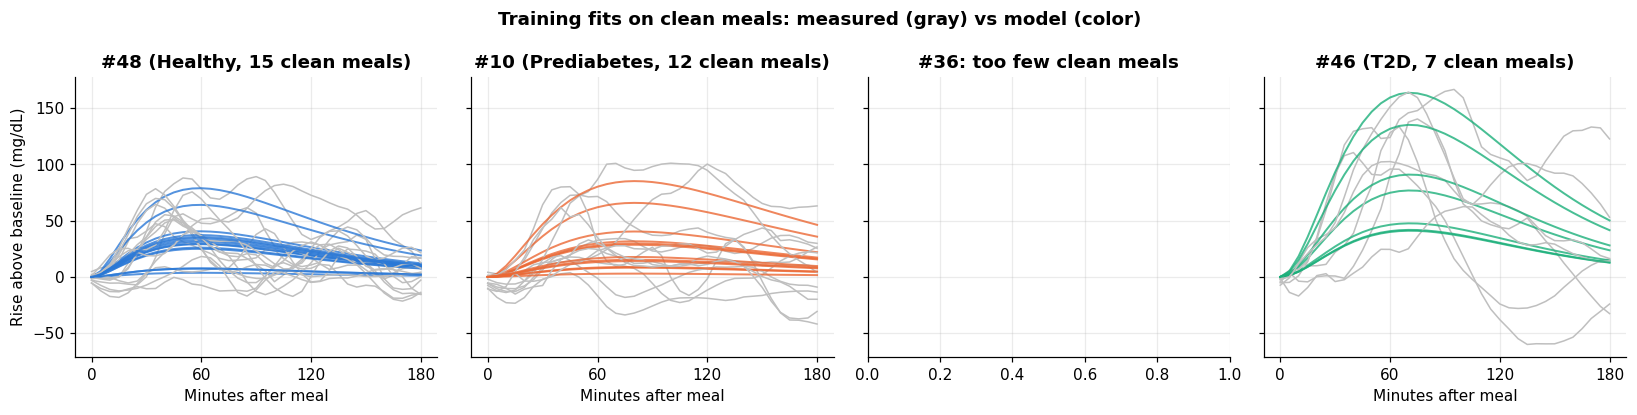

In [25]:
# Same four example people, now fitted on clean meals only
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, sid in zip(axes, examples):
    if sid not in fits_clean:
        ax.set_title(f"#{sid}: too few clean meals"); continue
    g = train_clean[train_clean.sid == sid]; f = fits_clean[sid]
    pred = simulate(f["ka"], f["SG"], f["SI"], g.carbs.values, g.Gb.values, g.alpha.iloc[0], f["s"])
    for o, p, b in zip(g.obs, pred, g.Gb):
        ax.plot(GRID, o - b, color="0.75", lw=1)
        ax.plot(GRID, p - b, color=GROUP_COLORS[params_clean.loc[sid, "group"]], lw=1.3, alpha=0.8)
    ax.set(title=f"#{sid} ({params_clean.loc[sid, 'group']}, {len(g)} clean meals)",
           xlabel="Minutes after meal", xticks=range(0, 181, 60))
axes[0].set_ylabel("Rise above baseline (mg/dL)")
fig.suptitle("Training fits on clean meals: measured (gray) vs model (color)", fontweight="bold")
plt.tight_layout(); plt.show()

### Does it predict held-out meals better?

We compare the original model (trained on all meals) with the clean-trained model on the same people's test meals, two ways:
- **Clean test meals:** a fair comparison, since this is the situation the model is meant for.
- **All test meals:** what you'd get in real use, where you can't always choose when people eat.

`bias` is the average signed error: positive means the model predicts glucose too high.

In [27]:
def predict_scores(fit_dict, df, label, s_rule="logged"):
    rows = []
    for sid, g in df[df.sid.isin(fit_dict)].groupby("sid"):
        f = fit_dict[sid]
        s = None if s_rule == "logged" else np.full(len(g), np.median(f["s"]))
        pred = simulate(f["ka"], f["SG"], f["SI"], g.carbs.values, g.Gb.values, g.alpha.iloc[0], s)
        for p, r in zip(pred, g.itertuples()):
            o = r.obs - r.Gb; seen = ~np.isnan(o)
            rows.append(dict(sid=sid, group=r.group, clean=r.clean, model=label,
                             bias=np.mean((p - r.Gb)[seen] - o[seen]), **score(p - r.Gb, o)))
    return pd.DataFrame(rows)

test_c = meals[(meals.split == "test") & meals.sid.isin(fits_clean)]
ppg_all = {sid: np.nanmean(rise(d) / d.carbs.values[:, None], 0) for sid, d in train.groupby("sid")}
base_rows = [dict(sid=r.sid, group=r.group, clean=r.clean, model="baseline: person per gram",
                  bias=np.nanmean(ppg_all[r.sid] * r.carbs - (r.obs - r.Gb)), **score(ppg_all[r.sid] * r.carbs, r.obs - r.Gb))
             for r in test_c.itertuples()]
clean_eval = pd.concat([pd.DataFrame(base_rows),
                        predict_scores(fits, test_c, "ODE trained on all meals"),
                        predict_scores(fits_clean, test_c, "ODE trained on clean meals")], ignore_index=True)

cols = ["rmse", "peak_err", "tpeak_err", "bias"]
print(f"Clean test meals ({test_c.clean.sum()}):")
display(clean_eval[clean_eval.clean].groupby("model")[cols].median().round(1))
print(f"All test meals ({len(test_c)}):")
display(clean_eval.groupby("model")[cols].median().round(1))
print("Median RMSE on clean test meals, by group:")
clean_eval[clean_eval.clean].pivot_table(index="model", columns="group", values="rmse", aggfunc="median").reindex(columns=GROUP_ORDER).round(1)

Clean test meals (168):


,rmse,peak_err,tpeak_err,bias
model,,,,
ODE trained on all meals,22.9,23.1,30.0,1.7
ODE trained on clean meals,22.2,18.5,30.0,7.1
baseline: person per gram,22.1,18.8,25.0,-2.9


All test meals (227):


,rmse,peak_err,tpeak_err,bias
model,,,,
ODE trained on all meals,23.8,22.3,30.0,3.2
ODE trained on clean meals,24.6,21.3,30.0,9.6
baseline: person per gram,22.9,20.1,25.0,-1.6


Median RMSE on clean test meals, by group:


group,Healthy,Prediabetes,T2D
model,,,
ODE trained on all meals,15.1,23.0,30.7
ODE trained on clean meals,15.0,22.6,40.9
baseline: person per gram,16.0,25.0,32.9


### A second issue this uncovered: the carb correction

Remember the per-meal **effective carbs** factor `s` (1 = the log was right). During training, the fitter routinely sets it **below 1**: in effect, the model concludes that less glucose reaches the blood than the logged carbs imply. That could mean people over-estimate carbs, or that the fixed absorption constants (90% absorbed, glucose spreading through 1.88 dL/kg) are too generous for this group.

At test time we've been using the logs as written (s = 1), so predictions overshoot. A fair fix, using only training information, is to apply each person's **typical** training correction (the median of their s values) to their test meals.

In [29]:
s_summary = pd.DataFrame({
    "trained on all meals": pd.Series({sid: np.median(f["s"]) for sid, f in fits.items()}),
    "trained on clean meals": pd.Series({sid: np.median(f["s"]) for sid, f in fits_clean.items()}),
}).join(flags.set_index("sid")["group"])
print("Median carb correction per person, by group (1 = logs taken as-is):")
display(s_summary.groupby("group").median().reindex(GROUP_ORDER).round(2))

s_eval = pd.concat([predict_scores(fits, test_c, "all meals, logged carbs"),
                    predict_scores(fits, test_c, "all meals, person's typical correction", "person"),
                    predict_scores(fits_clean, test_c, "clean meals, logged carbs"),
                    predict_scores(fits_clean, test_c, "clean meals, person's typical correction", "person")], ignore_index=True)
print("Clean test meals:")
display(s_eval[s_eval.clean].groupby("model")[cols].median().round(1))
print("Median RMSE on clean test meals, by group:")
s_eval[s_eval.clean].pivot_table(index="model", columns="group", values="rmse", aggfunc="median").reindex(columns=GROUP_ORDER).round(1)

Median carb correction per person, by group (1 = logs taken as-is):


,trained on all meals,trained on clean meals
group,,
Healthy,0.78,0.74
Prediabetes,0.86,0.86
T2D,0.99,0.88


Clean test meals:


,rmse,peak_err,tpeak_err,bias
model,,,,
"all meals, logged carbs",22.9,23.1,30.0,1.7
"all meals, person's typical correction",21.0,22.9,30.0,-0.2
"clean meals, logged carbs",22.2,18.5,30.0,7.1
"clean meals, person's typical correction",20.8,22.8,30.0,3.6


Median RMSE on clean test meals, by group:


group,Healthy,Prediabetes,T2D
model,,,
"all meals, logged carbs",15.1,23.0,30.7
"all meals, person's typical correction",15.3,21.6,34.8
"clean meals, logged carbs",15.0,22.6,40.9
"clean meals, person's typical correction",15.1,20.5,38.3


### Do the parameters reflect metabolic health more clearly?

In [31]:
def rho(df, p):
    return spearmanr(df[p], df["A1c"])[0]

param_check = pd.DataFrame({
    "trained on all meals": {**{f"ρ({p}, A1c)": rho(params, p) for p in ["ka", "SG", "SI"]},
                             "people with SI stuck at lower limit": int((params.SI < 2e-6).sum()),
                             "people": len(params)},
    "trained on clean meals": {**{f"ρ({p}, A1c)": rho(params_clean, p) for p in ["ka", "SG", "SI"]},
                               "people with SI stuck at lower limit": int((params_clean.SI < 2e-6).sum()),
                               "people": len(params_clean)},
})
param_check.round(2)

,trained on all meals,trained on clean meals
"ρ(ka, A1c)",-0.00,0.18
"ρ(SG, A1c)",-0.61,-0.71
"ρ(SI, A1c)",-0.56,-0.18
people with SI stuck at lower limit,10.00,3.00
people,36.00,35.00


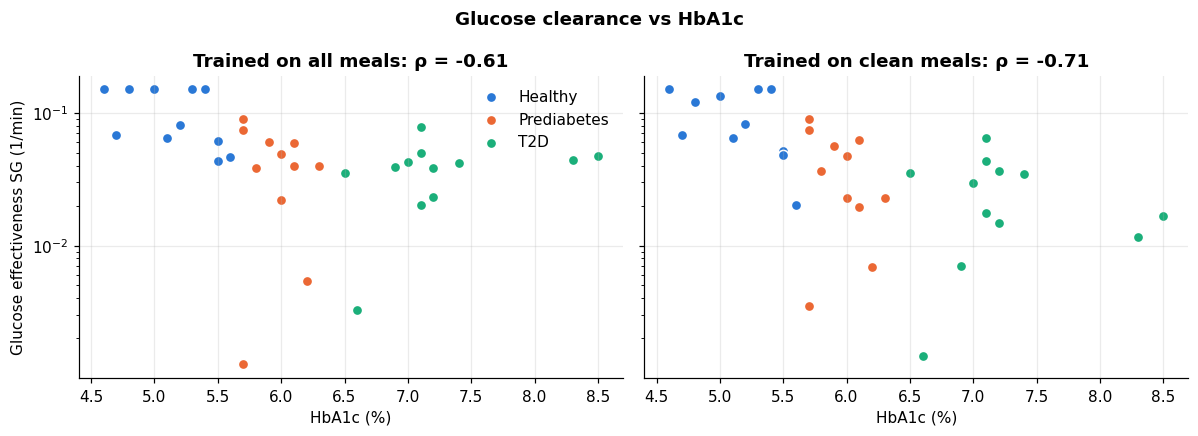

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (df, title) in zip(axes, [(params, "Trained on all meals"), (params_clean, "Trained on clean meals")]):
    for g in GROUP_ORDER:
        d = df[df.group == g]
        ax.scatter(d["A1c"], d["SG"], color=GROUP_COLORS[g], edgecolor="white", s=45, label=g)
    ax.set(yscale="log", xlabel="HbA1c (%)", title=f"{title}: ρ = {rho(df, 'SG'):.2f}")
axes[0].set_ylabel("Glucose effectiveness SG (1/min)")
axes[0].legend(frameon=False)
fig.suptitle("Glucose clearance vs HbA1c", fontweight="bold")
plt.tight_layout(); plt.show()

### What this step tells us

The refit used 35 people; 404 of 597 training meals were clean.

**What got better: the parameters.**
- **Glucose clearance (SG) tracks HbA1c more strongly:** ρ = −0.71, up from −0.61.
- **T2D now separates from prediabetes.** Trained on all meals, both groups had the same median SG (about 0.040/min). Trained on clean meals, T2D drops to about 0.024 while prediabetes stays near 0.037. Messy meals had been hiding a real difference.
- **Fewer collapsed insulin-sensitivity estimates:** 3 people at the lower limit instead of 10. SI is still very small, though, and its earlier correlation with A1c mostly disappears (−0.18), confirming it was an artifact of hitting the limit rather than a real signal.
- **Peak height improved** on clean test meals (median error 18.5 vs 23.1 mg/dL).

**What didn't: prediction for T2D.**
- Overall, the clean-trained model is slightly better on clean test meals (RMSE 22.2 vs 22.9) and slightly worse on all test meals (24.6 vs 23.8). That's expected, since it never learned the messy cases.
- **For T2D it's clearly worse** (about 41 vs 31 mg/dL on clean test meals). It predicts glucose staying high for too long. The clean filter removes the most T2D meals (only 60% of T2D meals are clean, leaving about 10 clean training meals per T2D person vs 12–13 for the others), and with fewer meals the slow clearance it learns doesn't carry over to their later meals.

**The carb correction matters.** The model routinely shrinks logged carbs during training. Applying each person's typical correction at test time gives the best overall result so far (about 21 mg/dL RMSE on clean test meals, best for prediabetes), but it doesn't fix the T2D gap and even makes T2D slightly worse for the original model (34.8 vs 30.7).

**Decision for now:** sections 7–11 below still use the original model (`fits`, trained on all meals), so they stay comparable with the first run. The clean-trained model is the better one for **interpreting parameters**; for **prediction**, the open problems are T2D and absorption timing, both of which are addressed in `PINN_modeling.ipynb`.

## 7. How well does it predict meals it hasn't seen?

For each person's test meals the model uses that person's fitted ka, SG and SI, the meal's logged carbs (s = 1, since we can't know the logging error in advance) and the baseline at meal start.

In [35]:
rows = []
for sid, g in test.groupby("sid"):
    f = fits[sid]
    pred = simulate(f["ka"], f["SG"], f["SI"], g.carbs.values, g.Gb.values, g.alpha.iloc[0])
    for p, r in zip(pred, g.itertuples()):
        rows.append(dict(sid=sid, group=r.group, model="ODE", **score(p - r.Gb, r.obs - r.Gb)))
scores = pd.concat([baseline_scores, pd.DataFrame(rows)], ignore_index=True)

order = ["group_mean", "person_mean", "person_per_gram", "ODE"]
print("Median error on held-out meals (mg/dL; minutes for time to peak):")
display(scores.groupby("model")[["rmse", "peak_err", "tpeak_err"]].median().reindex(order).round(1))
print("Median RMSE by group:")
scores.pivot_table(index="group", columns="model", values="rmse", aggfunc="median").reindex(index=GROUP_ORDER, columns=order).round(1)

Median error on held-out meals (mg/dL; minutes for time to peak):


,rmse,peak_err,tpeak_err
model,,,
group_mean,26.4,22.5,30.0
person_mean,23.9,21.2,20.0
person_per_gram,23.3,20.6,25.0
ODE,23.9,23.1,30.0


Median RMSE by group:


model,group_mean,person_mean,person_per_gram,ODE
group,,,,
Healthy,20.0,16.5,17.0,16.4
Prediabetes,25.2,21.1,24.9,23.7
T2D,35.9,35.8,30.4,30.8


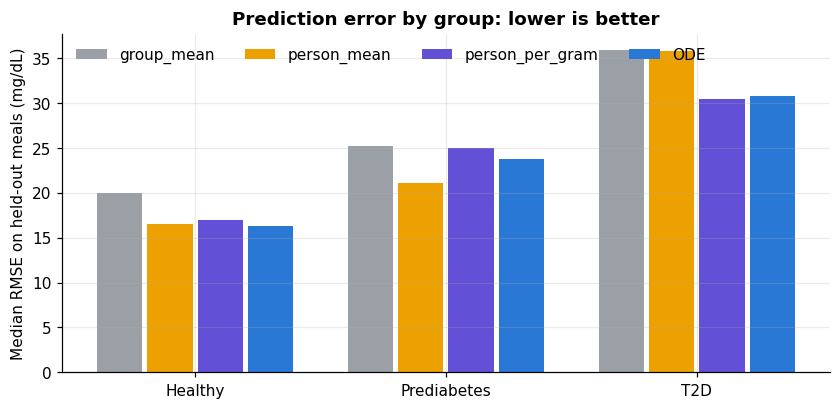

In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
tab = scores.pivot_table(index="group", columns="model", values="rmse", aggfunc="median").reindex(index=GROUP_ORDER, columns=order)
x = np.arange(len(GROUP_ORDER)); w = 0.2
for i, m in enumerate(order):
    ax.bar(x + (i - 1.5) * w, tab[m], width=w - 0.02, color=MODEL_COLORS[m], label=m)
ax.set_xticks(x, GROUP_ORDER)
ax.set(ylabel="Median RMSE on held-out meals (mg/dL)", title="Prediction error by group: lower is better")
ax.legend(frameon=False, ncols=4, loc="upper left")
plt.show()

## 8. A brand-new person, with no calibration

In [38]:
logp = np.log(params[["ka", "SG", "SI"]])
rows = []
for sid, g in meals.groupby("sid"):
    ka, SG, SI = np.exp(logp.drop(index=sid).median().values)          # everyone except this person
    pop_pred = simulate(ka, SG, SI, g.carbs.values, g.Gb.values, g.alpha.iloc[0])
    other_groups = {gr: np.nanmean(rise(d), 0) for gr, d in train[train.sid != sid].groupby("group")}
    for i, r in enumerate(g.itertuples()):
        if r.split != "test":
            continue
        o = r.obs - r.Gb
        rows.append(dict(sid=sid, group=r.group, model="ODE, population (no calibration)", **score(pop_pred[i] - r.Gb, o)))
        rows.append(dict(sid=sid, group=r.group, model="group mean (others)", **score(other_groups[r.group], o)))
new_person = pd.concat([pd.DataFrame(rows), scores[scores.model == "ODE"].assign(model="ODE, personalized")])
new_person.groupby("model")[["rmse", "peak_err", "tpeak_err"]].median().round(1)

,rmse,peak_err,tpeak_err
model,,,
"ODE, personalized",23.9,23.1,30.0
"ODE, population (no calibration)",27.9,23.8,30.0
group mean (others),27.3,22.4,35.0


**Reading this:** the gap between "population" and "personalized" is the value of calibration, meaning what you gain from a few days of a person's own data. It quantifies how much personal calibration is worth.

## 9. Do fitted parameters reflect metabolic health?

If the model captures real physiology, people with higher HbA1c should show slower glucose clearance. We use HbA1c as a continuous value (EDA 10.1) with Spearman rank correlation, which doesn't assume a straight-line relationship, and repeat the test after removing people whose diagnostic labels disagree and women under 45 (EDA 10.2).

In [41]:
def corr_table(df):
    out = {}
    for p in ["ka", "SG", "SI"]:
        rho, pval = spearmanr(df[p], df["A1c"])
        out[p] = {"rho": round(rho, 2), "p": round(pval, 4), "n": len(df)}
    return pd.DataFrame(out).T

subsets = {"all": params,
           "labels agree": params[params.groups_agree],
           "no women under 45": params[params.cycle_status != "<45: likely cycling"]}
pd.concat({k: corr_table(v) for k, v in subsets.items()}, axis=1)

all               labels agree               no women under 45          \
     rho       p     n          rho       p     n               rho       p   
ka -0.00  0.9857  36.0         0.13  0.5263  26.0             -0.03  0.8835   
SG -0.61  0.0001  36.0        -0.59  0.0015  26.0             -0.59  0.0005   
SI -0.56  0.0004  36.0        -0.57  0.0026  26.0             -0.54  0.0016   

          
       n  
ka  31.0  
SG  31.0  
SI  31.0

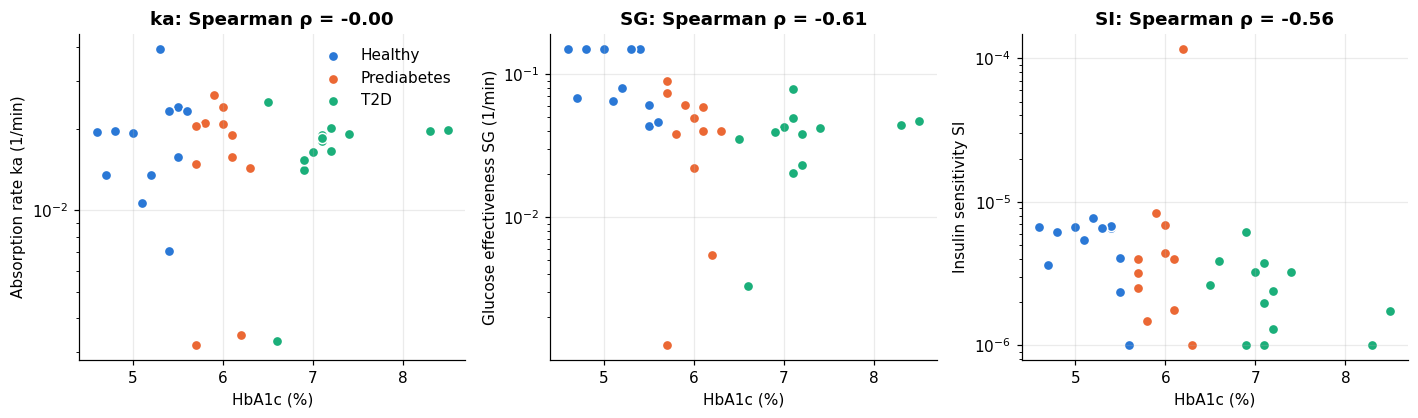

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, p, lab in zip(axes, ["ka", "SG", "SI"], ["Absorption rate ka (1/min)", "Glucose effectiveness SG (1/min)", "Insulin sensitivity SI"]):
    for g in GROUP_ORDER:
        d = params[params.group == g]
        ax.scatter(d["A1c"], d[p], color=GROUP_COLORS[g], edgecolor="white", s=45, label=g)
    rho = spearmanr(params[p], params["A1c"])[0]
    ax.set(yscale="log", xlabel="HbA1c (%)", ylabel=lab, title=f"{p}: Spearman ρ = {rho:.2f}")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 10. Save results

In [44]:
params.rename_axis("sid").to_csv(P / "model1_params.csv")
scores.to_csv(P / "model1_test_scores.csv", index=False)
new_person.to_csv(P / "model1_new_person_scores.csv", index=False)
print("Saved model1_params.csv, model1_test_scores.csv, model1_new_person_scores.csv to processed/")

Saved model1_params.csv, model1_test_scores.csv, model1_new_person_scores.csv to processed/


## 11. What we learned

Results are based on 36 people with enough meals (831 meals, 234 of them held out for testing).

1. **The fitting machinery works.** On 25 synthetic people it recovered absorption rate, glucose effectiveness and insulin sensitivity with median errors of about 2%, 7% and 8%.
2. **On held-out meals, the physics model matches the best simple baselines** (median RMSE 23.9 mg/dL vs 23.3 for a person's carb-scaled average and 23.9 for their plain average), using only three interpretable numbers per person. It clearly beats the group average (26.4), most of all in T2D (30.8 vs 35.9).
3. **Calibration is worth about 4 mg/dL.** Predicting a brand-new person from other people's parameters gives 27.9 mg/dL RMSE vs 23.9 when personalized, about 14% worse.
4. **Glucose effectiveness (SG) tracks HbA1c** (Spearman ρ = −0.61, p ≈ 0.0001): people with worse long-term control clear glucose more slowly after meals. It holds when people with disagreeing labels are removed (ρ = −0.59) and when women under 45 are removed (ρ = −0.59). Healthy people's median SG is about 3× that of the other two groups.
5. **Insulin sensitivity (SI) is not identifiable from these real curves.** It's recoverable on synthetic data, but on real data it collapses toward its lower limit (10 of 36 people sit at the bound, and the population median is tiny). One clearance rate explains how glucose comes back down; the delayed "second drain" isn't visible through the noise (unlogged eating, carb error, meal composition, no insulin data). SI's correlation with A1c largely mirrors SG's, so treat SG as **total effective clearance** and don't interpret SI on its own.
6. **Absorption rate doesn't differ by group** (absorption peaks about 52–54 minutes after eating in every group), and it's the model's main weakness: one number per person can't capture that fat, protein and fiber slow absorption, so time-to-peak error (30 min) is worse than the person's own average curve (20 min).

**Next step** (`PINN_modeling.ipynb`): keep this ODE as the backbone, and let a small neural network predict each meal's absorption rate and effective carbs from its fat, protein, fiber, time of day and meal type. Physics constrains the shape; the network learns what the physics leaves out. Success means better peak timing without losing the interpretable SG.